# Visualisasi — Gambar (sampel, anotasi, kesalahan)
**Kapan dipakai:** "seperti apa data gambarnya? apakah label/kotak benar? ukuran dan kelasnya
seimbang? gambar apa yang salah ditebak model?"

**Isi:** grid sampel per kelas, sebaran ukuran gambar, overlay bbox (label YOLO), overlay mask,
overlay keypoint (YOLO pose), sebaran kelas dan ukuran bbox, grid salah prediksi, gambar
interaktif plotly. Semua gambar disimpan di folder notebook.

**Data demo:** CIFAR-10 mini (klasifikasi), COCO8 (bbox YOLO), Penn-Fudan (mask pejalan kaki).

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import torch
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from torchvision import models, transforms
from ultralytics import YOLO

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision"   # GANTI saat lomba
WEIGHTS_FOLDER = "../../pretrained"
CIFAR_FOLDER = f"{DATA_FOLDER}/classification/cifar10_small"
COCO_FOLDER = f"{DATA_FOLDER}/detection/coco8"
PENN_FOLDER = f"{DATA_FOLDER}/detection/PennFudanPed"
PENN_EXT = ".png"     # ekstensi gambar Penn-Fudan
COCO_EXT = ".jpg"     # ekstensi gambar COCO8
EXAMPLE_IMAGE = f"{PENN_FOLDER}/PNGImages/FudanPed00001.png"
EXAMPLE_MASK = f"{PENN_FOLDER}/PedMasks/FudanPed00001_mask.png"

SEED = 42
BATCH_SIZE = 128   # gambar per batch saat ekstraksi fitur (kecilkan bila memori GPU penuh)
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Gaya grafik (sama di semua notebook visualisasi)
Font besar supaya terbaca di slide, palet tetap, garis tepi atas/kanan dimatikan.

In [3]:
PALETTE = ["#2E6FB7", "#F28E2B", "#3BA272", "#D1495B", "#7B5EA7", "#9AA0A6"]
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = PALETTE
plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 100, "savefig.dpi": 200,
    "font.size": 14, "axes.titlesize": 18, "axes.titleweight": "bold", "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
sns.set_palette(PALETTE)

## Baca data

In [4]:
train = pd.read_csv(f"{CIFAR_FOLDER}/train.csv")
test = pd.read_csv(f"{CIFAR_FOLDER}/test.csv")
test_key = pd.read_csv(f"{CIFAR_FOLDER}/test_labels.csv")
test["label"] = test_key["label"]   # urutan baris sama dengan test.csv
yolo_model = YOLO(f"{WEIGHTS_FOLDER}/yolov8n/yolov8n.pt")
class_names = yolo_model.names      # nomor kelas COCO -> nama kelas
classes = sorted(train["label"].unique())
print(train.shape, test.shape, len(classes), "kelas")
train.head(3)

(4000, 2) (1000, 3) 10 kelas


,path,label
0,train/airplane/0000.png,airplane
1,train/airplane/0001.png,airplane
2,train/airplane/0002.png,airplane


## 1. Grid sampel per kelas
**Kapan dipakai:** langkah pertama pada data gambar; memastikan label benar dan melihat variasi.
**Cara baca:** satu baris = satu kelas, 8 contoh acak. Cari gambar yang tidak cocok dengan
labelnya (label salah), gambar terlalu gelap/buram, atau variasi yang sangat besar.

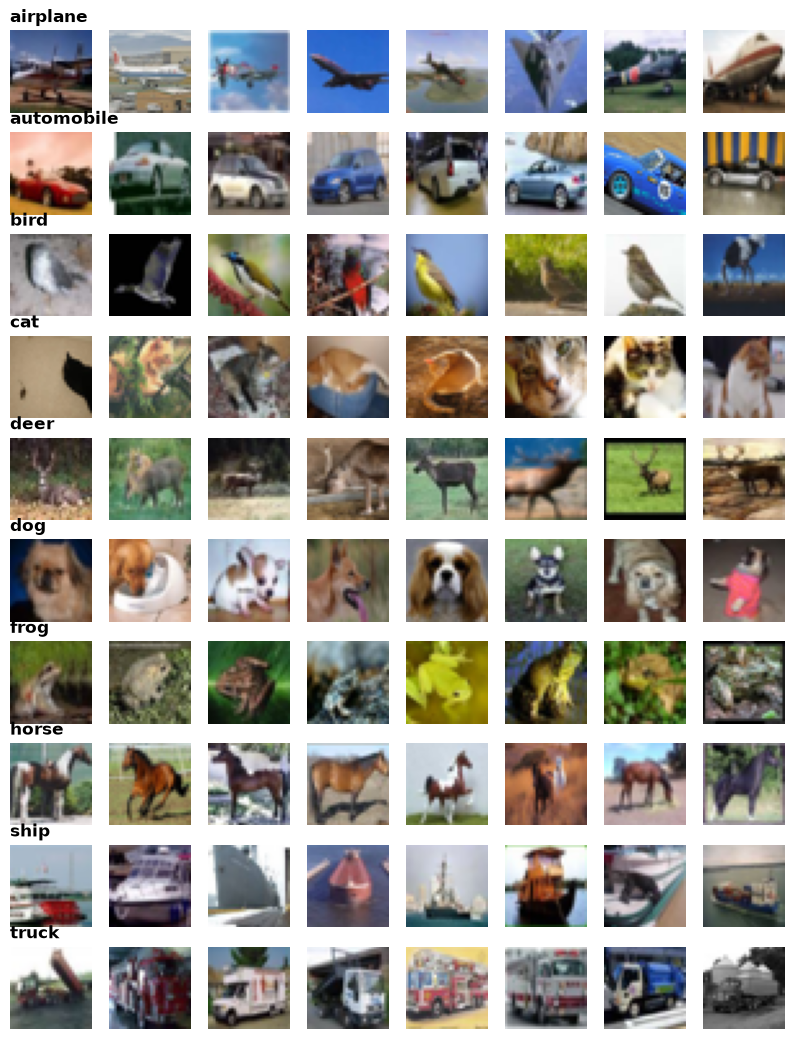

In [5]:
fig, axes = plt.subplots(len(classes), 8, figsize=(10, 13))
for i, name in enumerate(classes):
    in_class = train[train["label"] == name]
    examples = in_class.sample(8, random_state=SEED)
    for column, path in enumerate(examples["path"]):
        axes[i, column].imshow(Image.open(f"{CIFAR_FOLDER}/{path}"))
        axes[i, column].axis("off")
    axes[i, 0].set_title(name, loc="left", fontsize=12)
plt.savefig("gambar_grid_sampel.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Sebaran kelas dan ukuran gambar
**Kapan dipakai:** memutuskan resize, augmentasi, dan bobot kelas.
**Cara baca:** kiri = jumlah gambar per kelas (tidak seimbang?). Kanan = lebar vs tinggi gambar
(Penn-Fudan); titik menyebar = ukuran beragam, perlu resize ke ukuran seragam.

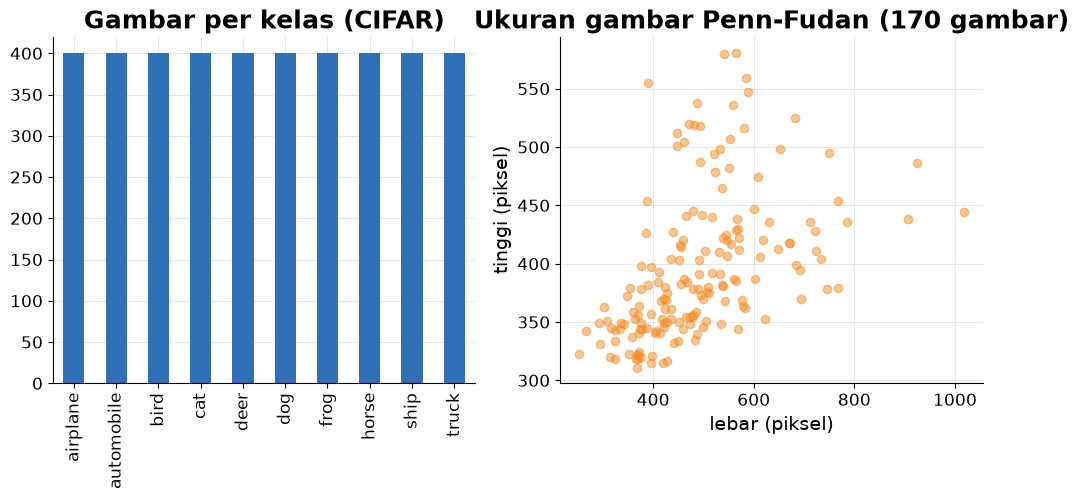

In [6]:
image_files = sorted(glob.glob(f"{PENN_FOLDER}/PNGImages/*{PENN_EXT}"))
image_sizes = []
for file in image_files:
    image_sizes.append(Image.open(file).size)   # (lebar, tinggi) tanpa membaca seluruh piksel
sizes = pd.DataFrame(image_sizes, columns=["width", "height"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
class_counts = train["label"].value_counts()
class_counts.sort_index().plot.bar(color=BLUE, ax=axes[0])
axes[0].set_title("Gambar per kelas (CIFAR)")
axes[0].set_xlabel("")
axes[1].scatter(sizes["width"], sizes["height"], alpha=0.5, color=ORANGE)
axes[1].set_title(f"Ukuran gambar Penn-Fudan ({len(sizes)} gambar)")
axes[1].set_xlabel("lebar (piksel)")
axes[1].set_ylabel("tinggi (piksel)")
plt.savefig("gambar_kelas_dan_ukuran.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Overlay bounding box (label YOLO)
**Kapan dipakai:** memeriksa anotasi deteksi sebelum latih (kotak salah posisi/kelas?).
**Cara baca:** file label YOLO berisi `kelas x_tengah y_tengah lebar tinggi` (nilai 0-1);
di sini dikembalikan ke piksel dan digambar bersama nama kelasnya.

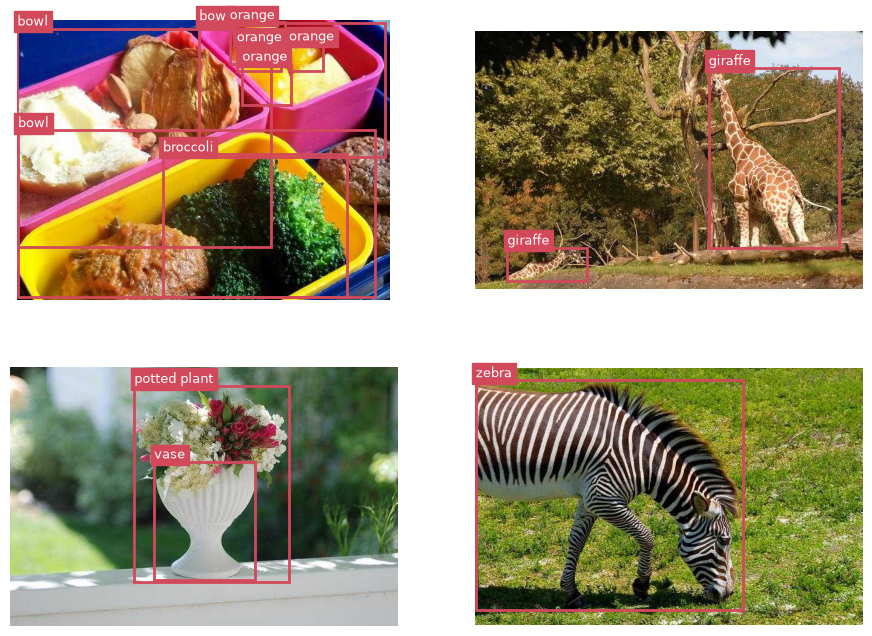

In [7]:
coco_files = sorted(glob.glob(f"{COCO_FOLDER}/images/train/*{COCO_EXT}"))
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, file in zip(axes.ravel(), coco_files[:4]):
    photo = Image.open(file)
    ax.imshow(photo)
    ax.axis("off")
    file_name = os.path.splitext(os.path.basename(file))[0]   # "000000000009"
    label_file = f"{COCO_FOLDER}/labels/train/{file_name}.txt"
    for class_id, x_center, y_center, width, height in np.loadtxt(label_file, ndmin=2):
        left = (x_center - width / 2) * photo.width
        top = (y_center - height / 2) * photo.height
        box = plt.Rectangle((left, top), width * photo.width, height * photo.height,
                            fill=False, edgecolor=RED, linewidth=2)
        ax.add_patch(box)
        ax.text(left, top, class_names[int(class_id)], color="white", backgroundcolor=RED,
                fontsize=9, va="bottom")
# Label segmentasi YOLO (poligon): baris = kelas lalu pasangan x y; gambar dengan ax.fill(...)
plt.savefig("gambar_overlay_bbox.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Overlay mask (segmentasi instance)
**Kapan dipakai:** memeriksa mask segmentasi; sekaligus mendapat kotak dari mask.
**Cara baca:** warna transparan = satu objek (satu id per orang); kotak hitam dihitung dari
mask. Mask yang bocor ke latar atau terpotong tampak jelas.

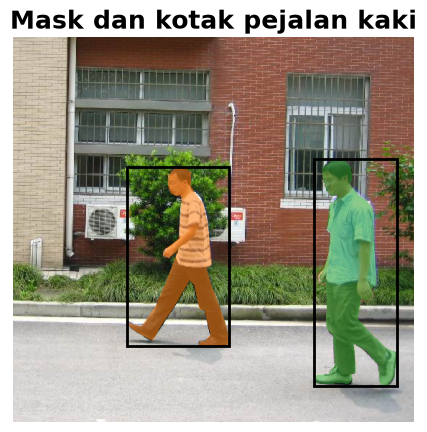

In [8]:
photo = Image.open(EXAMPLE_IMAGE)
mask = np.array(Image.open(EXAMPLE_MASK))     # 0 = latar, 1, 2, ... = orang ke-1, ke-2, ...
plt.imshow(photo)
plt.imshow(np.ma.masked_equal(mask, 0), cmap="tab10", alpha=0.55, vmin=0, vmax=9)
for object_id in np.unique(mask)[1:]:
    rows, columns = np.where(mask == object_id)
    width = columns.max() - columns.min()
    height = rows.max() - rows.min()
    box = plt.Rectangle((columns.min(), rows.min()), width, height, fill=False,
                        edgecolor="black", linewidth=2)
    plt.gca().add_patch(box)
plt.axis("off")
plt.title("Mask dan kotak pejalan kaki")
plt.savefig("gambar_overlay_mask.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Overlay keypoint (pose)
**Kapan dipakai:** data/tugas pose; memeriksa hasil model atau anotasi titik tubuh.
**Cara baca:** titik = sendi (hidung, bahu, siku, pinggul, lutut...), garis = tulang.
Titik yang melayang atau tertukar kiri-kanan = kesalahan.

WARNING NMS time limit 2.050s exceeded


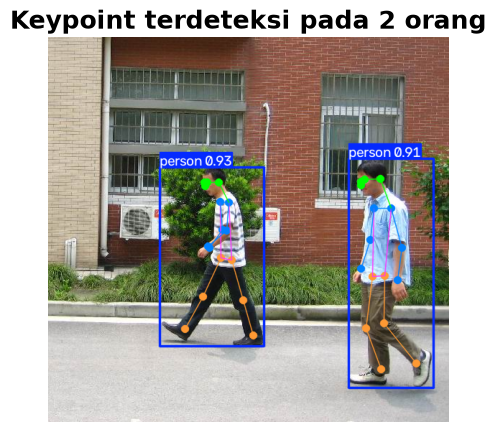

In [9]:
pose_model = YOLO(f"{WEIGHTS_FOLDER}/yolov8n_pose/yolov8n-pose.pt")
results = pose_model.predict(EXAMPLE_IMAGE, verbose=False)
result = results[0]
drawn = result.plot()                 # gambar BGR berisi titik dan garis
plt.imshow(drawn[:, :, ::-1])         # BGR dibalik ke RGB
plt.axis("off")
plt.title(f"Keypoint terdeteksi pada {len(result.keypoints.xy)} orang")
plt.savefig("gambar_overlay_keypoint.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Sebaran kelas dan ukuran bbox
**Kapan dipakai:** menentukan ukuran input model (objek kecil perlu resolusi besar) dan
mendeteksi kelas yang langka. **Cara baca:** kiri = jumlah objek per kelas; kanan = lebar vs
tinggi kotak relatif terhadap gambar (0-1, skala log). Titik di pojok kiri-bawah = objek kecil.

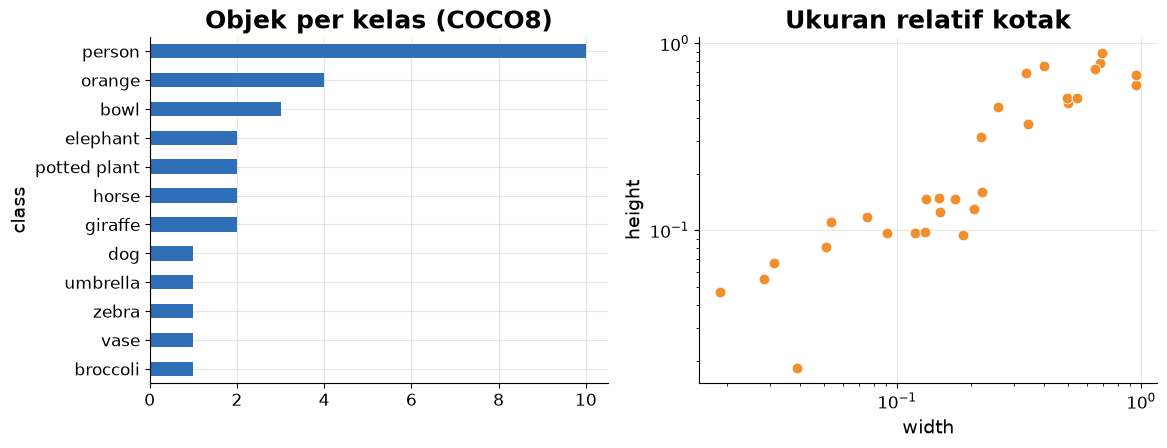

In [10]:
rows = []
for file in glob.glob(f"{COCO_FOLDER}/labels/*/*.txt"):
    for class_id, x_center, y_center, width, height in np.loadtxt(file, ndmin=2):
        rows.append([class_names[int(class_id)], width, height])
boxes = pd.DataFrame(rows, columns=["class", "width", "height"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
objects_per_class = boxes["class"].value_counts()
objects_per_class.sort_values().plot.barh(color=BLUE, ax=axes[0])
axes[0].set_title("Objek per kelas (COCO8)")
sns.scatterplot(data=boxes, x="width", y="height", color=ORANGE, s=60, ax=axes[1])
axes[1].set(xscale="log", yscale="log")
axes[1].set_title("Ukuran relatif kotak")
plt.savefig("gambar_distribusi_bbox.png", dpi=200, bbox_inches="tight")
plt.show()

## Model cepat untuk bahan grafik kesalahan
Fitur ResNet18 pretrained (tanpa latih ulang) + model sederhana. Fokus bukan di model.

**Langkah:** (1) ResNet18 tanpa lapisan akhir = pengubah gambar jadi 512 angka,
(2) semua gambar diubah per batch, (3) model dilatih pada angka-angka itu.

In [11]:
net = models.resnet18(weights=None)
weights = torch.load(f"{WEIGHTS_FOLDER}/resnet18/model.pth", map_location="cpu")
net.load_state_dict(weights)
net.fc = torch.nn.Identity()          # buang lapisan akhir -> keluaran = fitur
net.eval()
net = net.to(DEVICE)
mean_rgb = [0.485, 0.456, 0.406]
std_rgb = [0.229, 0.224, 0.225]
preprocess = transforms.Compose([
    transforms.Resize(112),
    transforms.ToTensor(),
    transforms.Normalize(mean_rgb, std_rgb),
])

all_paths = list(train["path"]) + list(test["path"])   # latih dulu, lalu uji
feature_batches = []
for start in range(0, len(all_paths), BATCH_SIZE):
    batch = []
    for path in all_paths[start:start + BATCH_SIZE]:
        image = Image.open(f"{CIFAR_FOLDER}/{path}").convert("RGB")
        batch.append(preprocess(image))
    with torch.no_grad():
        output = net(torch.stack(batch).to(DEVICE))
    feature_batches.append(output.cpu().numpy())
all_features = np.vstack(feature_batches)
print(all_features.shape)

(5000, 512)


In [12]:
scaler = StandardScaler()
X_train = scaler.fit_transform(all_features[:len(train)])
X_test = scaler.transform(all_features[len(train):])

model = LogisticRegression(max_iter=2000)
# model = SVC(probability=True)                  # sering lebih akurat, lebih lambat
# model = RandomForestClassifier(n_estimators=300)   # tanpa scaling pun jalan
model.fit(X_train, train["label"])
prediction = model.predict(X_test)
probabilities = model.predict_proba(X_test)
confidence = probabilities.max(axis=1)        # keyakinan = peluang kelas tebakan
print("akurasi uji:", round((prediction == test["label"]).mean(), 3))

akurasi uji: 0.757


## 7. Grid salah prediksi
**Kapan dipakai:** analisis kesalahan; mencari pola (kelas tertukar, label salah, gambar buruk).
**Cara baca:** 12 gambar yang salah ditebak dengan keyakinan tertinggi. Judul = label asli,
tebakan, dan keyakinan model. Keyakinan tinggi tapi salah sering berarti labelnya yang keliru.

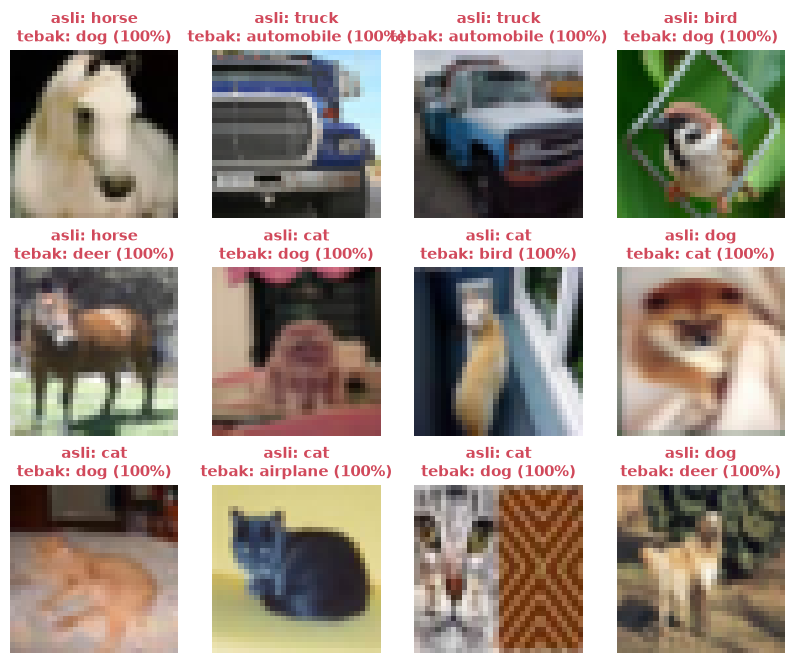

In [13]:
wrong_rows = np.where(prediction != test["label"].values)[0]   # nomor baris yang salah ditebak
wrong_confidence = confidence[wrong_rows]
order = np.argsort(-wrong_confidence)          # dari yang paling yakin
most_confident = wrong_rows[order][:12]
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, row in zip(axes.ravel(), most_confident):
    ax.imshow(Image.open(f"{CIFAR_FOLDER}/{test['path'][row]}"))
    ax.axis("off")
    title = f"asli: {test['label'][row]}\ntebak: {prediction[row]} ({confidence[row]:.0%})"
    ax.set_title(title, color=RED, fontsize=11)
plt.savefig("gambar_salah_prediksi.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Gambar interaktif (plotly)
**Kapan dipakai:** memperbesar detail gambar atau memeriksa koordinat piksel untuk anotasi.
**Cara baca:** arahkan kursor untuk melihat koordinat x, y dan nilai RGB; seret untuk zoom.

In [14]:
pixels = np.array(Image.open(EXAMPLE_IMAGE))
fig = px.imshow(pixels, title="Gambar interaktif (hover untuk koordinat dan RGB)")
fig.write_html("gambar_interaktif.html", include_plotlyjs=True)
fig.show()